<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Retrieval scope comes before ranking

**Which documents can a query retrieve before we interpret their BM25 scores?** We
will inspect the worker's English tokens, assemble a small corpus in SQL, search it
with a conjunctive or OR query, and join every returned hit back to its source.

Ten authored records contain eight short document strings, one empty string and one
missing text value. They are learning fixtures, not retrieved research or product
specifications. A ranking score is useful within its search context; it is not a
probability that a document is correct or useful.

## Choose the query's term requirement

`REQUIRE_ALL_TERMS=True` searches `battery storage`, whose default behavior in this
worker is conjunctive. The experiment sets it to `False`, producing the explicit OR
query `battery OR storage`. The corpus and English analyzer stay fixed. Restart and
run all after changing the boolean.

In [1]:
REQUIRE_ALL_TERMS = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from notebook_support import finish, prose, theme

if type(REQUIRE_ALL_TERMS) is not bool:
    raise ValueError("REQUIRE_ALL_TERMS must be True or False.")
coverage = ranked = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tantivy/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tantivy/notebooks/pyproject.toml.

## Attach the release and declare corpus eligibility

The literal native release location requires no Rust build. The inventory retains
empty and missing text separately; this example indexes only nonempty supplied text.
That exclusion is an explicit notebook choice, not a claim that empty documents
cannot be indexed. Stable integer document IDs let us join hits back safely.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tantivy' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-tantivy@v0.4.0');
CREATE TABLE inputs AS SELECT *,CASE WHEN text IS NULL THEN 'Missing text'
 WHEN length(trim(text))=0 THEN 'Empty text' ELSE 'Indexed text' END AS input_state
FROM read_json('fixtures/corpus.json');
CREATE TABLE corpus AS SELECT doc_id,text FROM inputs WHERE input_state='Indexed text';
SELECT doc_id,text,input_state FROM inputs ORDER BY doc_id;

,doc_id,text,input_state
0,101,Battery storage for solar microgrids,Indexed text
1,102,Batteries store energy in modular storage systems,Indexed text
2,103,Storage maintenance for battery banks and batt...,Indexed text
3,104,Battery maintenance and charging checks,Indexed text
4,105,Cold storage warehouse temperature checks,Indexed text
5,106,Archival storage and document retention,Indexed text
6,107,Solar panels and wind turbines,Indexed text
7,108,Battery battery battery overview,Indexed text
8,109,,Empty text
9,110,None,Missing text


## Inspect the terms the search analyzer sees

The one-argument `tokenize` lowercases words. The English overload also applies
Snowball stemming, which maps `battery` and `batteries` to the same stem. Search
uses the English analyzer. `stem` is a useful scalar probe for individual words;
`supported_languages()` describes the tokenizer's available language options.

The coverage grid below counts each query stem's occurrences in each indexed
document. It explains lexical eligibility for these two plain terms. It is not a
general replacement for Tantivy's parser, which also supports more complex syntax.

In [4]:
%%sql
CREATE TABLE analyzed AS SELECT doc_id,text,tantivy.main.tokenize(text) AS plain_tokens,
 tantivy.main.tokenize(text,'english') AS english_tokens FROM corpus;
CREATE TABLE query_terms AS SELECT DISTINCT unnest(tantivy.main.tokenize('battery storage','english')) AS term;
CREATE TABLE term_coverage AS SELECT a.doc_id,a.text,q.term,
 list_count(list_filter(a.english_tokens,lambda x: x=q.term)) AS occurrences
FROM analyzed a CROSS JOIN query_terms q;
SELECT doc_id,plain_tokens,english_tokens FROM analyzed ORDER BY doc_id;

,doc_id,plain_tokens,english_tokens
0,101,"[battery, storage, for, solar, microgrids]","[batteri, storag, for, solar, microgrid]"
1,102,"[batteries, store, energy, in, modular, storag...","[batteri, store, energi, in, modular, storag, ..."
2,103,"[storage, maintenance, for, battery, banks, an...","[storag, mainten, for, batteri, bank, and, bat..."
3,104,"[battery, maintenance, and, charging, checks]","[batteri, mainten, and, charg, check]"
4,105,"[cold, storage, warehouse, temperature, checks]","[cold, storag, warehous, temperatur, check]"
5,106,"[archival, storage, and, document, retention]","[archiv, storag, and, document, retent]"
6,107,"[solar, panels, and, wind, turbines]","[solar, panel, and, wind, turbin]"
7,108,"[battery, battery, battery, overview]","[batteri, batteri, batteri, overview]"


In [5]:
%%sql coverage <<
SELECT doc_id,text,term,occurrences FROM term_coverage ORDER BY doc_id,term;

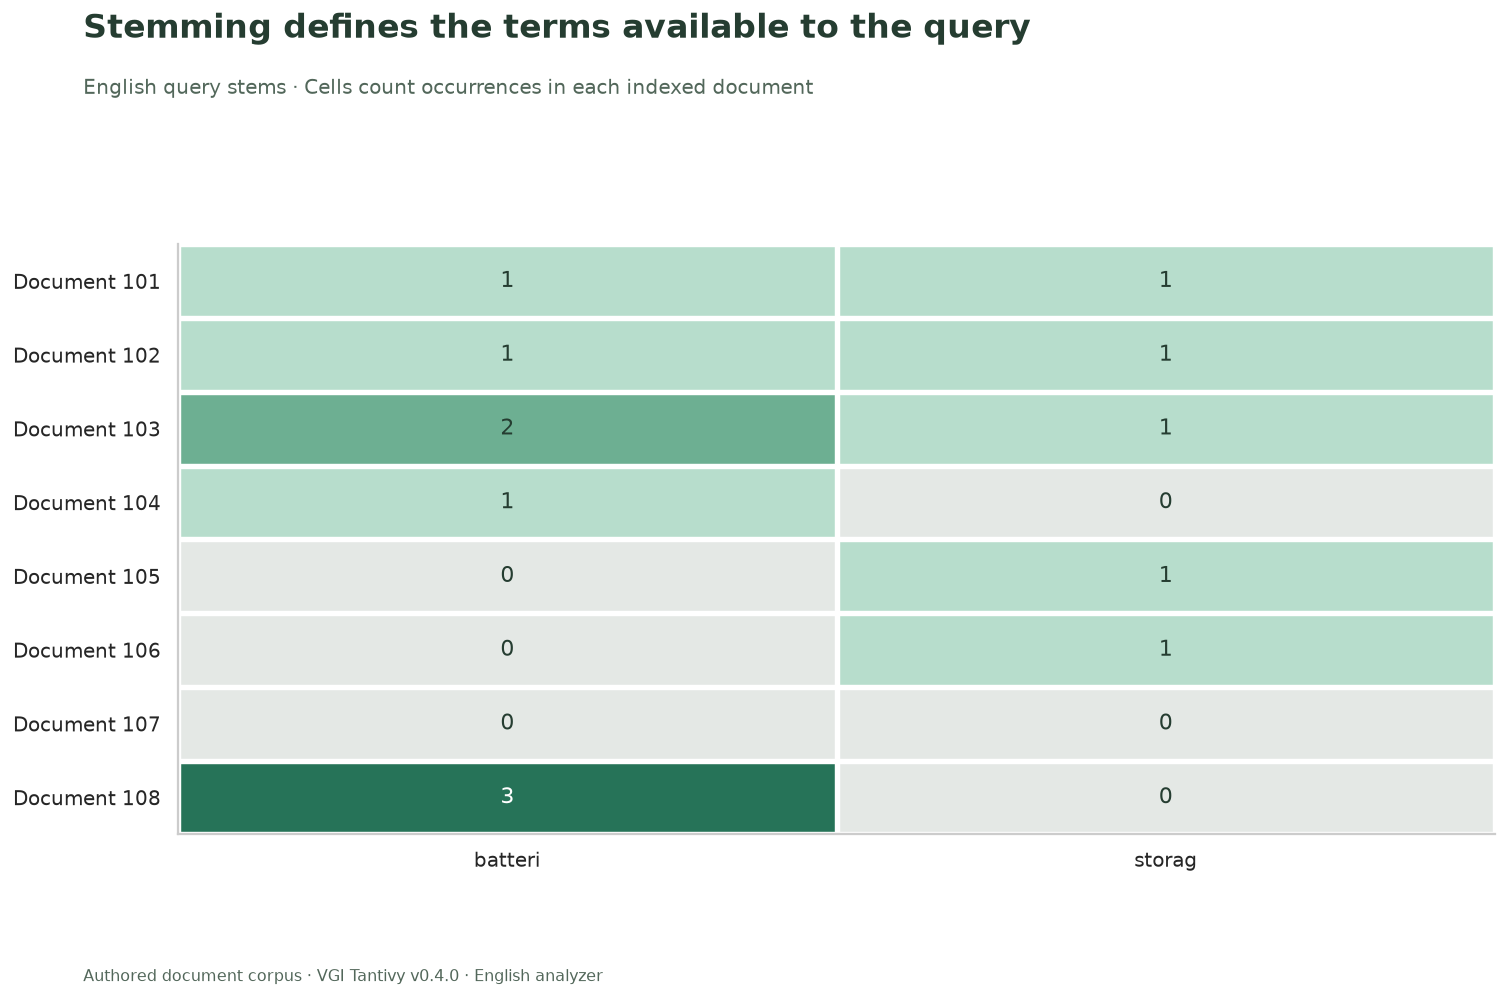

**3 indexed documents contain both query stems**, while **7 contain at least one**. Repeated battery terms add occurrences but do not satisfy a missing storage term. The grid stays fixed when only the query operator changes.

In [6]:
matrix = coverage.pivot(index="doc_id", columns="term", values="occurrences")
fig, ax = plt.subplots(figsize=(12, 7.8))
ax.imshow(
    matrix.values,
    cmap=ListedColormap(["#e4e8e5", "#b7ddcc", "#6daf92", "#267358"]),
    vmin=0,
    vmax=3,
    aspect="auto",
)
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix)), [f"Document {i}" for i in matrix.index])
ax.set_xticks(np.arange(-0.5, len(matrix.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(matrix), 1), minor=True)
ax.grid(False)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
for y, row in enumerate(matrix.values):
    for x, v in enumerate(row):
        ax.text(
            x,
            y,
            str(int(v)),
            ha="center",
            va="center",
            fontsize=12,
            color="white" if v == 3 else "#253d31",
        )
finish(
    fig,
    "Stemming defines the terms available to the query",
    "English query stems · Cells count occurrences in each indexed document",
    "01_term_coverage.png",
    bottom=0.11,
)
both = int((matrix > 0).all(axis=1).sum())
either = int((matrix > 0).any(axis=1).sum())
prose(
    f"**{both} indexed documents contain both query stems**, while **{either} contain at least one**. "
    "Repeated battery terms add occurrences but do not satisfy a missing storage term. The grid stays fixed when only the query operator changes."
)

## Assemble the corpus in SQL and materialize one search

The table function accepts a constant JSON payload. SQL constructs the `{id,text}`
array in stable ID order; a folded bridge quotes that exact payload and query for
the visible function call. This avoids relying on session variables across
JupySQL's separate cursors. No search runs in the bridge.

Each search builds a fresh in-memory index and discards it afterwards. Materializing
the result means tables and plots reuse the same call. The worker returns at most
10,000 hits; this eight-document corpus is comfortably below that limit.

In [7]:
%%sql
CREATE TABLE search_request AS SELECT to_json(list(struct_pack(id:=doc_id,text:=text) ORDER BY doc_id))::VARCHAR AS docs_json,
 CASE WHEN {{ REQUIRE_ALL_TERMS }} THEN 'battery storage' ELSE 'battery OR storage' END AS query
FROM corpus;
SELECT query,json_array_length(docs_json) AS indexed_documents FROM search_request;

,query,indexed_documents
0,battery storage,8


In [8]:
docs_json, query = con.execute("SELECT docs_json,query FROM search_request").fetchone()
docs_sql = "'" + docs_json.replace("'", "''") + "'"
query_sql = "'" + query.replace("'", "''") + "'"

In [9]:
%%sql
CREATE TABLE search_hits AS SELECT * FROM tantivy.main.bm25_search({{ docs_sql }},{{ query_sql }});
CREATE TABLE ranked_hits AS SELECT row_number() OVER(ORDER BY h.score DESC,h.doc_id) AS rank,
 h.doc_id,h.score,c.text,list_sort(list_intersect(a.english_tokens,(SELECT list(term) FROM query_terms))) AS matching_terms
FROM search_hits h JOIN corpus c USING(doc_id) JOIN analyzed a USING(doc_id);
SELECT i.doc_id,i.input_state,r.rank,r.score,i.text FROM inputs i LEFT JOIN ranked_hits r USING(doc_id) ORDER BY i.doc_id;

,doc_id,input_state,rank,score,text
0,101,Indexed text,1,1.022998,Battery storage for solar microgrids
1,102,Indexed text,3,0.886092,Batteries store energy in modular storage systems
2,103,Indexed text,2,1.015658,Storage maintenance for battery banks and batt...
3,104,Indexed text,<NA>,NaN,Battery maintenance and charging checks
4,105,Indexed text,<NA>,NaN,Cold storage warehouse temperature checks
5,106,Indexed text,<NA>,NaN,Archival storage and document retention
6,107,Indexed text,<NA>,NaN,Solar panels and wind turbines
7,108,Indexed text,<NA>,NaN,Battery battery battery overview
8,109,Empty text,<NA>,NaN,
9,110,Missing text,<NA>,NaN,None


## Interpret rank within the chosen search context

A NULL score in the left-joined inventory means no returned hit, not a zero relevance
measurement. For this bounded corpus, documents without a hit either fail the term
requirement or were excluded for empty/missing text. The chart shows returned hits
only and breaks score ties by document ID.

BM25 uses corpus statistics and the indexed terms. Scores are not probabilities,
quality judgments, or counts of matched terms. Compare ranks and scores only with
the corpus, analyzer and query context in view; there is no universal score threshold.

In [10]:
%%sql ranked <<
SELECT rank,doc_id,text,score,matching_terms FROM ranked_hits ORDER BY rank;

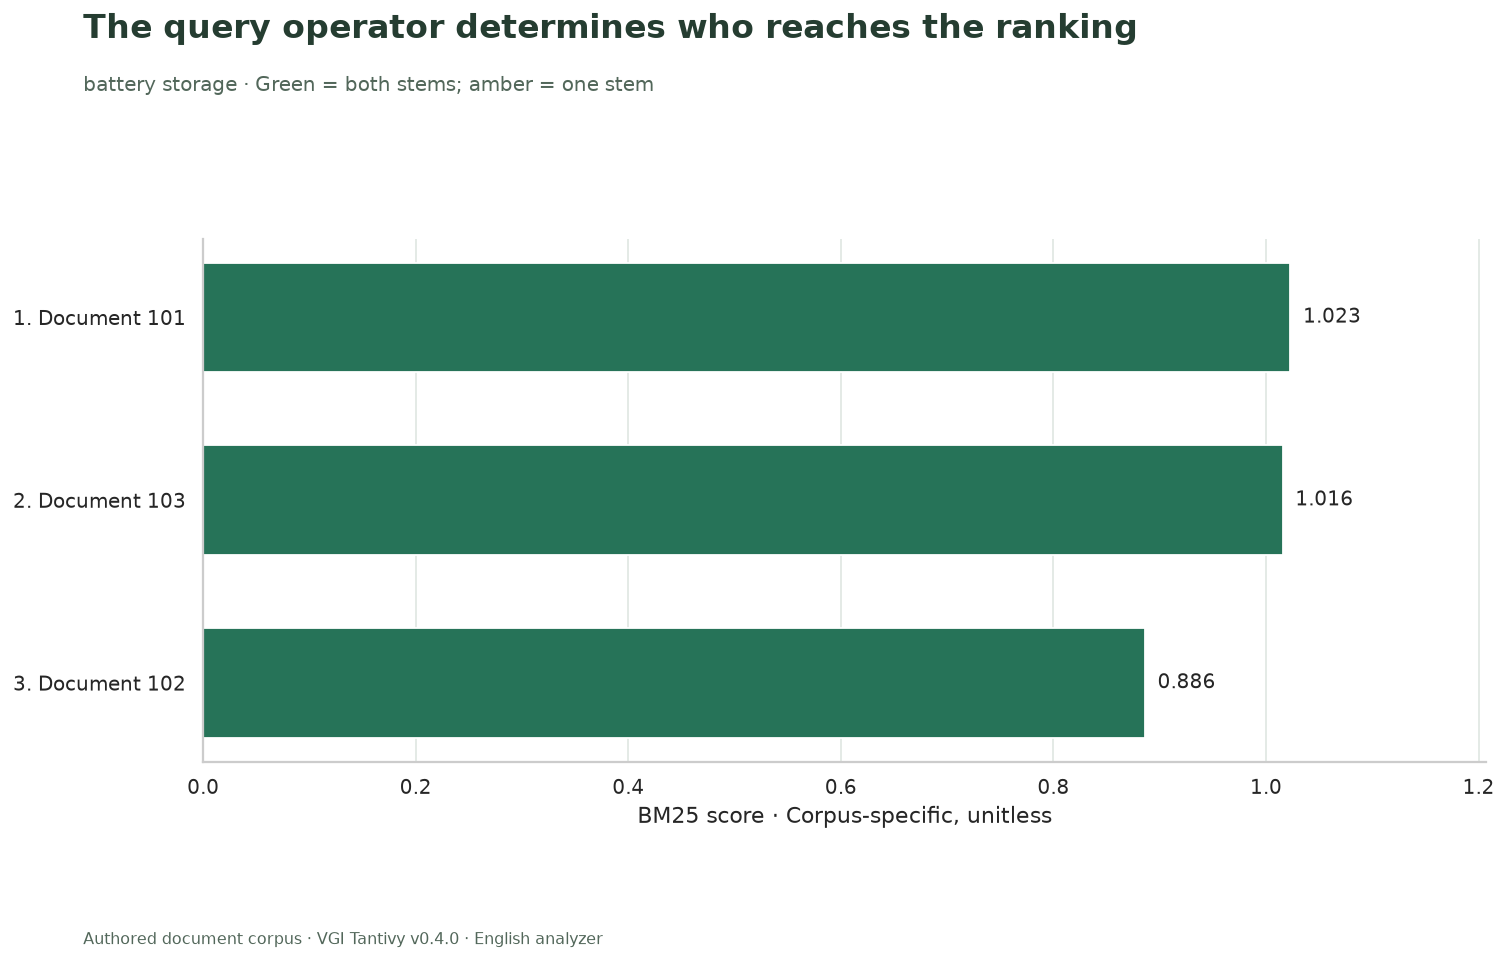

,rank,doc_id,text,score,matching_terms
0,1,101,Battery storage for solar microgrids,1.022998,"[batteri, storag]"
1,2,103,Storage maintenance for battery banks and batt...,1.015658,"[batteri, storag]"
2,3,102,Batteries store energy in modular storage systems,0.886092,"[batteri, storag]"


The query returns **3 of 8 indexed documents**. Document **101** ranks first in this run. Consult the joined text and matching terms before interpreting the rank. A lexical match does not establish that the document answers a question.

In [11]:
fig, ax = plt.subplots(figsize=(12, 7.5))
labels = [f"{int(r.rank)}. Document {r.doc_id}" for r in ranked.itertuples()]
colors = [
    "#267358" if len(r.matching_terms) == len(matrix.columns) else "#c57b40"
    for r in ranked.itertuples()
]
bars = ax.barh(labels, ranked.score, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{s:.3f}" for s in ranked.score], padding=7, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, float(ranked.score.max()) * 1.18)
ax.set_xlabel("BM25 score · Corpus-specific, unitless")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "The query operator determines who reaches the ranking",
    f"{query} · Green = both stems; amber = one stem",
    "02_ranked_hits.png",
    bottom=0.12,
)
display(ranked)
prose(
    f"The query returns **{len(ranked)} of {len(matrix)} indexed documents**. "
    f"Document **{int(ranked.iloc[0].doc_id)}** ranks first in this run. "
    "Consult the joined text and matching terms before interpreting the rank. A lexical match does not establish that the document answers a question."
)

## Keep one-document score probes separate

`bm25_score` builds a separate one-document index for each row. It can answer an
ad-hoc match probe, but its corpus statistics differ from the shared-corpus search.
The table below demonstrates that distinction for the top-ranked document. It does
not convert one scale into the other, and we do not rank the corpus using these
independent scalar scores.

In [12]:
%%sql
CREATE TABLE single_document_probe AS SELECT r.doc_id,r.score AS shared_corpus_score,
 tantivy.main.bm25_score(r.text,q.query) AS one_document_score
FROM ranked_hits r CROSS JOIN search_request q WHERE r.rank=1;
SELECT * FROM single_document_probe;

,doc_id,shared_corpus_score,one_document_score
0,101,1.022998,0.575364


## Verify inventory, token eligibility and ranked joins

For these simple plain-term queries, the token coverage grid supplies an independent
SQL check of expected AND/OR membership. We also verify source IDs, ordering and
positive returned scores without asserting exact floating-point values.

In [13]:
%%sql checks <<
SELECT 'All ten input IDs are retained' AS check_name,
 (SELECT count(*)=10 AND count(DISTINCT doc_id)=10 FROM inputs) AS passed
UNION ALL SELECT 'Eight nonempty supplied texts form the corpus',
 (SELECT count(*)=8 AND bool_and(text IS NOT NULL AND length(trim(text))>0) FROM corpus)
UNION ALL SELECT 'Empty and missing text remain separate exclusions',
 (SELECT input_state='Empty text' FROM inputs WHERE doc_id=109)
 AND (SELECT input_state='Missing text' FROM inputs WHERE doc_id=110)
UNION ALL SELECT 'Both English query stems are represented in coverage',
 (SELECT count(*)=2 FROM query_terms) AND (SELECT count(*)=16 FROM term_coverage)
UNION ALL SELECT 'Plural and singular battery share an English stem',
 tantivy.main.stem('battery','english')=tantivy.main.stem('batteries','english')
UNION ALL SELECT 'Serialized corpus preserves its source row count',
 (SELECT json_array_length(docs_json)=(SELECT count(*) FROM corpus) FROM search_request)
UNION ALL SELECT 'Hit IDs are unique and map to corpus records',
 (SELECT count(*)=count(DISTINCT doc_id) FROM search_hits)
 AND NOT EXISTS(SELECT 1 FROM search_hits h LEFT JOIN corpus c USING(doc_id) WHERE c.doc_id IS NULL)
UNION ALL SELECT 'Each hit agrees with the selected plain-term requirement',
 NOT EXISTS(SELECT 1 FROM (SELECT doc_id,CASE WHEN {{ REQUIRE_ALL_TERMS }} THEN bool_and(occurrences>0) ELSE bool_or(occurrences>0) END AS expected_hit
 FROM term_coverage GROUP BY doc_id) e LEFT JOIN search_hits h USING(doc_id)
 WHERE e.expected_hit<>(h.doc_id IS NOT NULL))
UNION ALL SELECT 'Returned scores are finite and positive',
 (SELECT bool_and(isfinite(score) AND score>0) FROM search_hits)
UNION ALL SELECT 'Ranks are contiguous and descending by score',
 (SELECT min(rank)=1 AND max(rank)=count(*) FROM ranked_hits)
 AND NOT EXISTS(SELECT 1 FROM (SELECT score,lag(score) OVER(ORDER BY rank) AS previous FROM ranked_hits) WHERE score>previous)
UNION ALL SELECT 'Empty and missing text never enter the result',
 NOT EXISTS(SELECT 1 FROM search_hits WHERE doc_id IN (109,110))
UNION ALL SELECT 'Top-document scalar probe is a positive separate score',
 (SELECT count(*)=1 AND bool_and(one_document_score>0 AND isfinite(one_document_score)) FROM single_document_probe);

In [14]:
display(checks)
assert checks.passed.fillna(False).all(), checks.loc[~checks.passed.fillna(False)]
assert len(ranked) == (both if REQUIRE_ALL_TERMS else either)
assert len(ranked) == con.execute("SELECT count(*) FROM search_hits").fetchone()[0]
prose(
    f"**{len(checks)} SQL checks and two hit-count reconciliations passed.** The demonstration checks retrieval and joins, not semantic answer quality."
)

,check_name,passed
0,All ten input IDs are retained,True
1,Eight nonempty supplied texts form the corpus,True
2,Empty and missing text remain separate exclusions,True
3,Both English query stems are represented in co...,True
4,Plural and singular battery share an English stem,True
5,Serialized corpus preserves its source row count,True
6,Hit IDs are unique and map to corpus records,True
7,Each hit agrees with the selected plain-term r...,True
8,Returned scores are finite and positive,True
9,Ranks are contiguous and descending by score,True


**12 SQL checks and two hit-count reconciliations passed.** The demonstration checks retrieval and joins, not semantic answer quality.

## Experiment: broaden the query to OR

Change **`REQUIRE_ALL_TERMS=True` to `False`**, restart and run all. Predict that the
coverage grid stays identical while documents containing just one query stem enter
the ranking. Compare the hit IDs and joined text before comparing numeric scores.
The repeated-battery document can now be retrieved despite lacking storage.

This changes query semantics over the same corpus. It does not add knowledge, assess
truth, or establish user relevance. Reset to **`True`** for the saved conjunctive
search. For later experiments, changing the corpus is a separate intervention that
also changes BM25 statistics; document that context explicitly.

In [15]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)